# K-Means++ on the Wine Dataset

Wine dataset (13 features, 3 classes) projected to 2D with PCA, clustered with K-Means, K-Means (Immediate Update) and K-Means++.

## 1. Import Libraries


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.datasets import load_wine
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score,
    adjusted_rand_score,
    confusion_matrix,
    f1_score,
    normalized_mutual_info_score,
    precision_score,
    recall_score,
    silhouette_score,
)

sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.dpi'] = 110

def dist(a, b):
    # euclidean distance done by hand, no numpy.linalg
    tot = 0.0
    i = 0
    while i < len(a):
        d = a[i] - b[i]
        tot = tot + d * d
        i = i + 1
    return tot ** 0.5

def pick_random_points(X, K, seed):
    # choose K random data points without repeating, done the slow way
    aa = np.random.default_rng(seed)
    n = len(X)
    used = []
    out = []
    while len(out) < K:
        i = int(aa.integers(0, n))
        if used.count(i) == 0:
            used.append(i)
            out.append(list(X[i]))
    return out

def to_labels(clusters, n):
    # turn the list of index-lists back into one label per point
    lab = [0] * n
    k = 0
    while k < len(clusters):
        for idx in clusters[k]:
            lab[idx] = k
        k = k + 1
    return lab

def nearest_centroid(sample, centroids, K):
    best = 0
    best_d = dist(sample, centroids[0])
    k = 1
    while k < K:
        dd = dist(sample, centroids[k])
        if dd < best_d:
            best_d = dd
            best = k
        k = k + 1
    return best

def mean_of_points(X, idxs, n_feat):
    # average of the points at idxs, point by point
    s = [0.0] * n_feat
    for idx in idxs:
        j = 0
        while j < n_feat:
            s[j] = s[j] + X[idx][j]
            j = j + 1
    cnt = len(idxs)
    out = []
    j = 0
    while j < n_feat:
        out.append(s[j] / cnt)
        j = j + 1
    return out

class KMeans:
    def __init__(self, K, max_iters=100, random_state=272):
        self.K = K
        self.max_iters = max_iters
        self.random_state = random_state
        self.clusters = [[] for _ in range(self.K)]
        self.centroids = None
        self.inertia_ = None

    def fit(self, X):
        self.X = X
        self.n = len(X)
        self.n_feat = len(X[0])
        self.centroids = pick_random_points(X, self.K, self.random_state)
        for it in range(self.max_iters):
            self.clusters = self._assign(self.centroids)
            old = [list(c) for c in self.centroids]
            self.centroids = self._new_centroids(self.clusters)
            if self._done(old, self.centroids):
                break
        return to_labels(self.clusters, self.n)

    def _assign(self, centroids):
        clusters = [[] for _ in range(self.K)]
        i = 0
        while i < self.n:
            c = nearest_centroid(self.X[i], centroids, self.K)
            clusters[c].append(i)
            i = i + 1
        return clusters

    def _new_centroids(self, clusters):
        out = []
        k = 0
        while k < self.K:
            if len(clusters[k]) == 0:
                out.append(list(self.centroids[k]))
            else:
                out.append(mean_of_points(self.X, clusters[k], self.n_feat))
            k = k + 1
        return out

    def _done(self, old, new):
        k = 0
        while k < self.K:
            if dist(old[k], new[k]) > 0:
                return False
            k = k + 1
        return True

    def predict(self, X):
        lab = []
        i = 0
        while i < len(X):
            lab.append(nearest_centroid(X[i], self.centroids, self.K))
            i = i + 1
        return lab


class KMeansImmediate:
    def __init__(self, K, max_iters=100, random_state=272):
        self.K = K
        self.max_iters = max_iters
        self.random_state = random_state
        self.clusters = [[] for _ in range(self.K)]
        self.centroids = None

    def fit(self, X):
        self.X = X
        self.n = len(X)
        self.n_feat = len(X[0])
        self.centroids = pick_random_points(X, self.K, self.random_state)
        labels = [0] * self.n
        for it in range(self.max_iters):
            moved = False
            i = 0
            while i < self.n:
                nc = nearest_centroid(self.X[i], self.centroids, self.K)
                if nc != labels[i]:
                    moved = True
                    labels[i] = nc
                k = 0
                while k < self.K:
                    idxs = []
                    j = 0
                    while j < self.n:
                        if labels[j] == k:
                            idxs.append(j)
                        j = j + 1
                    if len(idxs) != 0:
                        self.centroids[k] = mean_of_points(self.X, idxs, self.n_feat)
                    k = k + 1
                i = i + 1
            if not moved:
                break
        self.labels_ = labels
        return labels

    def predict(self, X):
        lab = []
        i = 0
        while i < len(X):
            lab.append(nearest_centroid(X[i], self.centroids, self.K))
            i = i + 1
        return lab


class KMeansPP:
    def __init__(self, K, max_iters=100, random_state=272):
        self.K = K
        self.max_iters = max_iters
        self.random_state = random_state
        self.clusters = [[] for _ in range(self.K)]
        self.centroids = None

    def fit(self, X):
        self.X = X
        self.n = len(X)
        self.n_feat = len(X[0])
        self.centroids = self._pp_init(X, self.K, self.random_state)
        for it in range(self.max_iters):
            self.clusters = self._assign(self.centroids)
            old = [list(c) for c in self.centroids]
            self.centroids = self._new_centroids(self.clusters)
            if self._done(old, self.centroids):
                break
        return to_labels(self.clusters, self.n)

    def _pp_init(self, X, K, seed):
        aa = np.random.default_rng(seed)
        n = len(X)
        C = [list(X[int(aa.integers(0, n))])]
        # D[i] = squared distance of point i to the closest centroid so far
        D = []
        i = 0
        while i < n:
            D.append(dist(X[i], C[0]) ** 2)
            i = i + 1
        for j in range(1, K):
            tot = 0.0
            i = 0
            while i < n:
                tot = tot + D[i]
                i = i + 1
            pick = int(aa.integers(0, n))
            if tot > 0:
                # pick by hand: walk a random number across the probabilities
                r = aa.random() * tot
                acc = 0.0
                i = 0
                while i < n:
                    acc = acc + D[i]
                    if acc >= r:
                        pick = i
                        break
                    i = i + 1
            C.append(list(X[pick]))
            i = 0
            while i < n:
                nd = dist(X[i], C[j]) ** 2
                if nd < D[i]:
                    D[i] = nd
                i = i + 1
        return C

    def _assign(self, centroids):
        clusters = [[] for _ in range(self.K)]
        i = 0
        while i < self.n:
            c = nearest_centroid(self.X[i], centroids, self.K)
            clusters[c].append(i)
            i = i + 1
        return clusters

    def _new_centroids(self, clusters):
        out = []
        k = 0
        while k < self.K:
            if len(clusters[k]) == 0:
                out.append(list(self.centroids[k]))
            else:
                out.append(mean_of_points(self.X, clusters[k], self.n_feat))
            k = k + 1
        return out

    def _done(self, old, new):
        k = 0
        while k < self.K:
            if dist(old[k], new[k]) > 0:
                return False
            k = k + 1
        return True

    def predict(self, X):
        lab = []
        i = 0
        while i < len(X):
            lab.append(nearest_centroid(X[i], self.centroids, self.K))
            i = i + 1
        return lab


## 2. Load Wine Dataset


In [2]:
wine = load_wine(as_frame=False)
Xw = wine.data
yw = list(wine.target)
pca = PCA(n_components=2, random_state=42).fit(Xw)
X2 = pca.transform(Xw)
print('explained variance:', np.round(pca.explained_variance_ratio_, 3))
print('classes:', np.unique(yw), 'samples:', len(Xw))

explained variance: [0.998 0.002]
classes: [0 1 2] samples: 178


## 3. Dataset Info (pandas)


In [3]:
import pandas as pd

df = pd.DataFrame(wine.data, columns=wine.feature_names)
df['class'] = wine.target
print('shape:', df.shape)


shape: (178, 14)


In [4]:
df.head()


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,class
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [5]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64
 13  class           

In [6]:
df.describe()


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,class
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258,0.938202
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474,0.775035
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000,0.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000,0.000000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000,1.000000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000,2.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000,2.000000


In [7]:
df["class"].value_counts().to_frame("count")


,count
class,
1,71
0,59
2,48


In [8]:
df.isnull().sum().to_frame("nulls")


,nulls
alcohol,0
malic_acid,0
ash,0
alcalinity_of_ash,0
magnesium,0
total_phenols,0
flavanoids,0
nonflavanoid_phenols,0
proanthocyanins,0
color_intensity,0


## 4. Data Before and After PCA


In [9]:
import pandas as pd

before = pd.DataFrame(Xw, columns=wine.feature_names)
after = pd.DataFrame(X2, columns=['PC1', 'PC2'])

print('before PCA  shape:', before.shape)
print(before.head())
print()
print('after PCA   shape:', after.shape)
print(after.head())


before PCA  shape: (178, 13)
   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   od280/od315_of_diluted_wines  

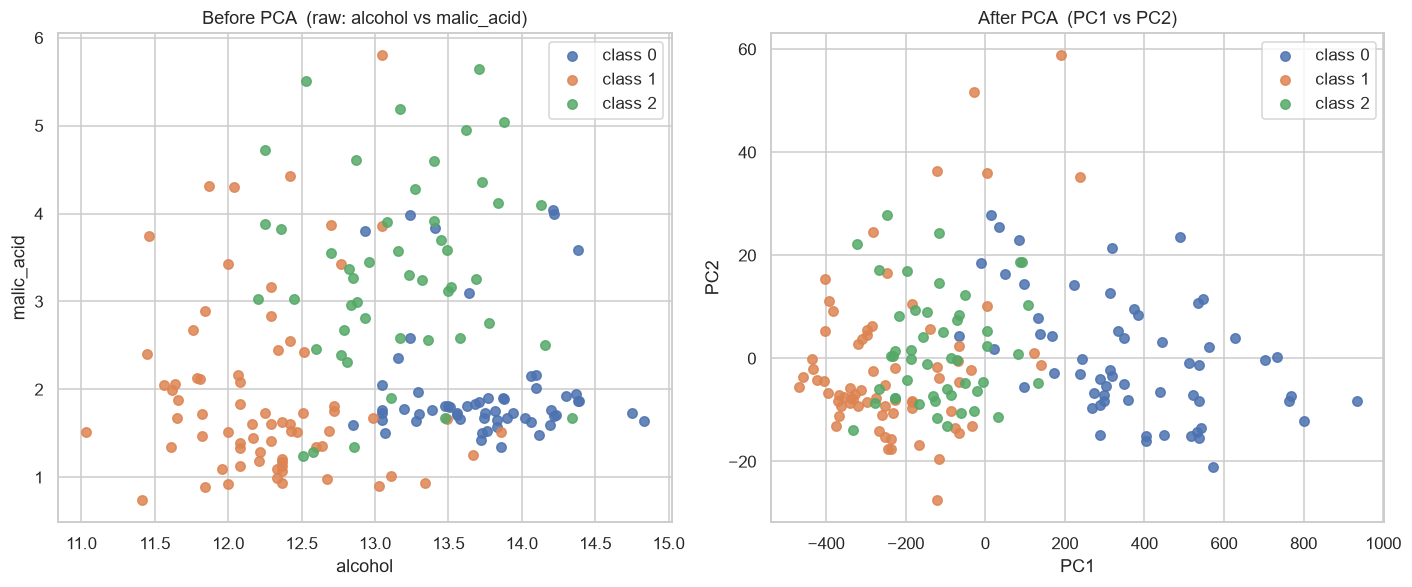

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))

# before PCA: scatter the first two raw features, colored by class
f0, f1 = wine.feature_names[0], wine.feature_names[1]
for c in [0, 1, 2]:
    pts = Xw[np.array(yw) == c]
    ax[0].scatter(pts[:, 0], pts[:, 1], s=38, alpha=0.85, label='class ' + str(c))
ax[0].set_title('Before PCA  (raw: ' + f0 + ' vs ' + f1 + ')')
ax[0].set_xlabel(f0)
ax[0].set_ylabel(f1)
ax[0].legend()

# after PCA: scatter the two principal components, colored by class
for c in [0, 1, 2]:
    pts = X2[np.array(yw) == c]
    ax[1].scatter(pts[:, 0], pts[:, 1], s=38, alpha=0.85, label='class ' + str(c))
ax[1].set_title('After PCA  (PC1 vs PC2)')
ax[1].set_xlabel('PC1')
ax[1].set_ylabel('PC2')
ax[1].legend()

plt.tight_layout()
plt.show()


## 5. Train-Test Split


In [11]:
from sklearn.model_selection import train_test_split

Xtr, Xte, ytr, yte = train_test_split(
    X2, yw, test_size=0.2, random_state=42, stratify=yw
)
print('train:', len(Xtr), 'test:', len(Xte))


train: 142 test: 36


## 6. Train Model


In [12]:
k = 3
km   = KMeans(K=3, max_iters=150, random_state=3)
ytr_km   = km.fit(Xtr)
kimm = KMeansImmediate(K=3, max_iters=150, random_state=3)
ytr_kimm = kimm.fit(Xtr)
kpp  = KMeansPP(K=3, max_iters=150, random_state=3)
ytr_kpp  = kpp.fit(Xtr)
print('KMeans     centroids:', [[round(v,2) for v in c] for c in km.centroids])
print('KMeansImm  centroids:', [[round(v,2) for v in c] for c in kimm.centroids])
print('KMeansPP   centroids:', [[round(v,2) for v in c] for c in kpp.centroids])


KMeans     centroids: [[np.float64(-280.11), np.float64(-2.52)], [np.float64(-5.95), np.float64(4.5)], [np.float64(425.59), np.float64(-1.47)]]
KMeansImm  centroids: [[np.float64(-230.28), np.float64(-2.53)], [np.float64(138.4), np.float64(7.45)], [np.float64(504.6), np.float64(-3.21)]]
KMeansPP   centroids: [[np.float64(-5.95), np.float64(4.5)], [np.float64(425.59), np.float64(-1.47)], [np.float64(-280.11), np.float64(-2.52)]]


## 7. Step-by-Step Convergence


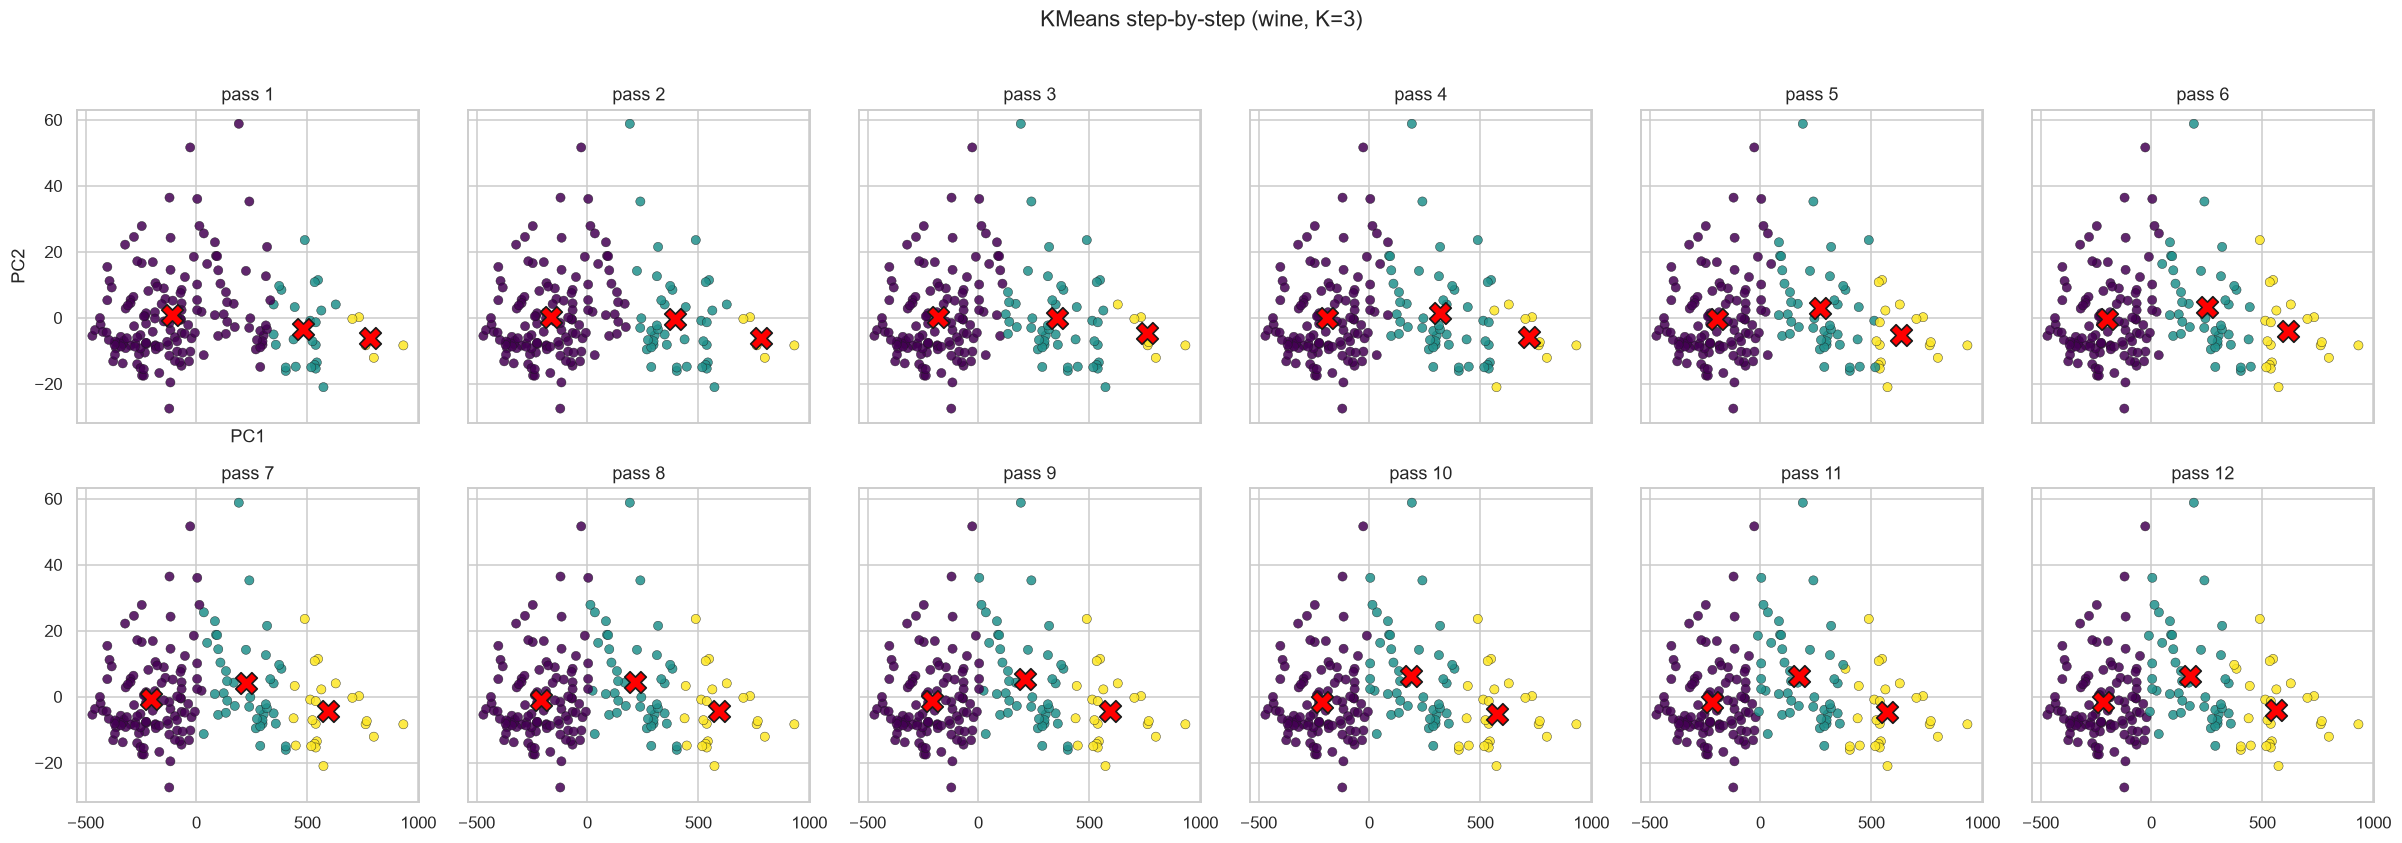

KMeans passes: 16


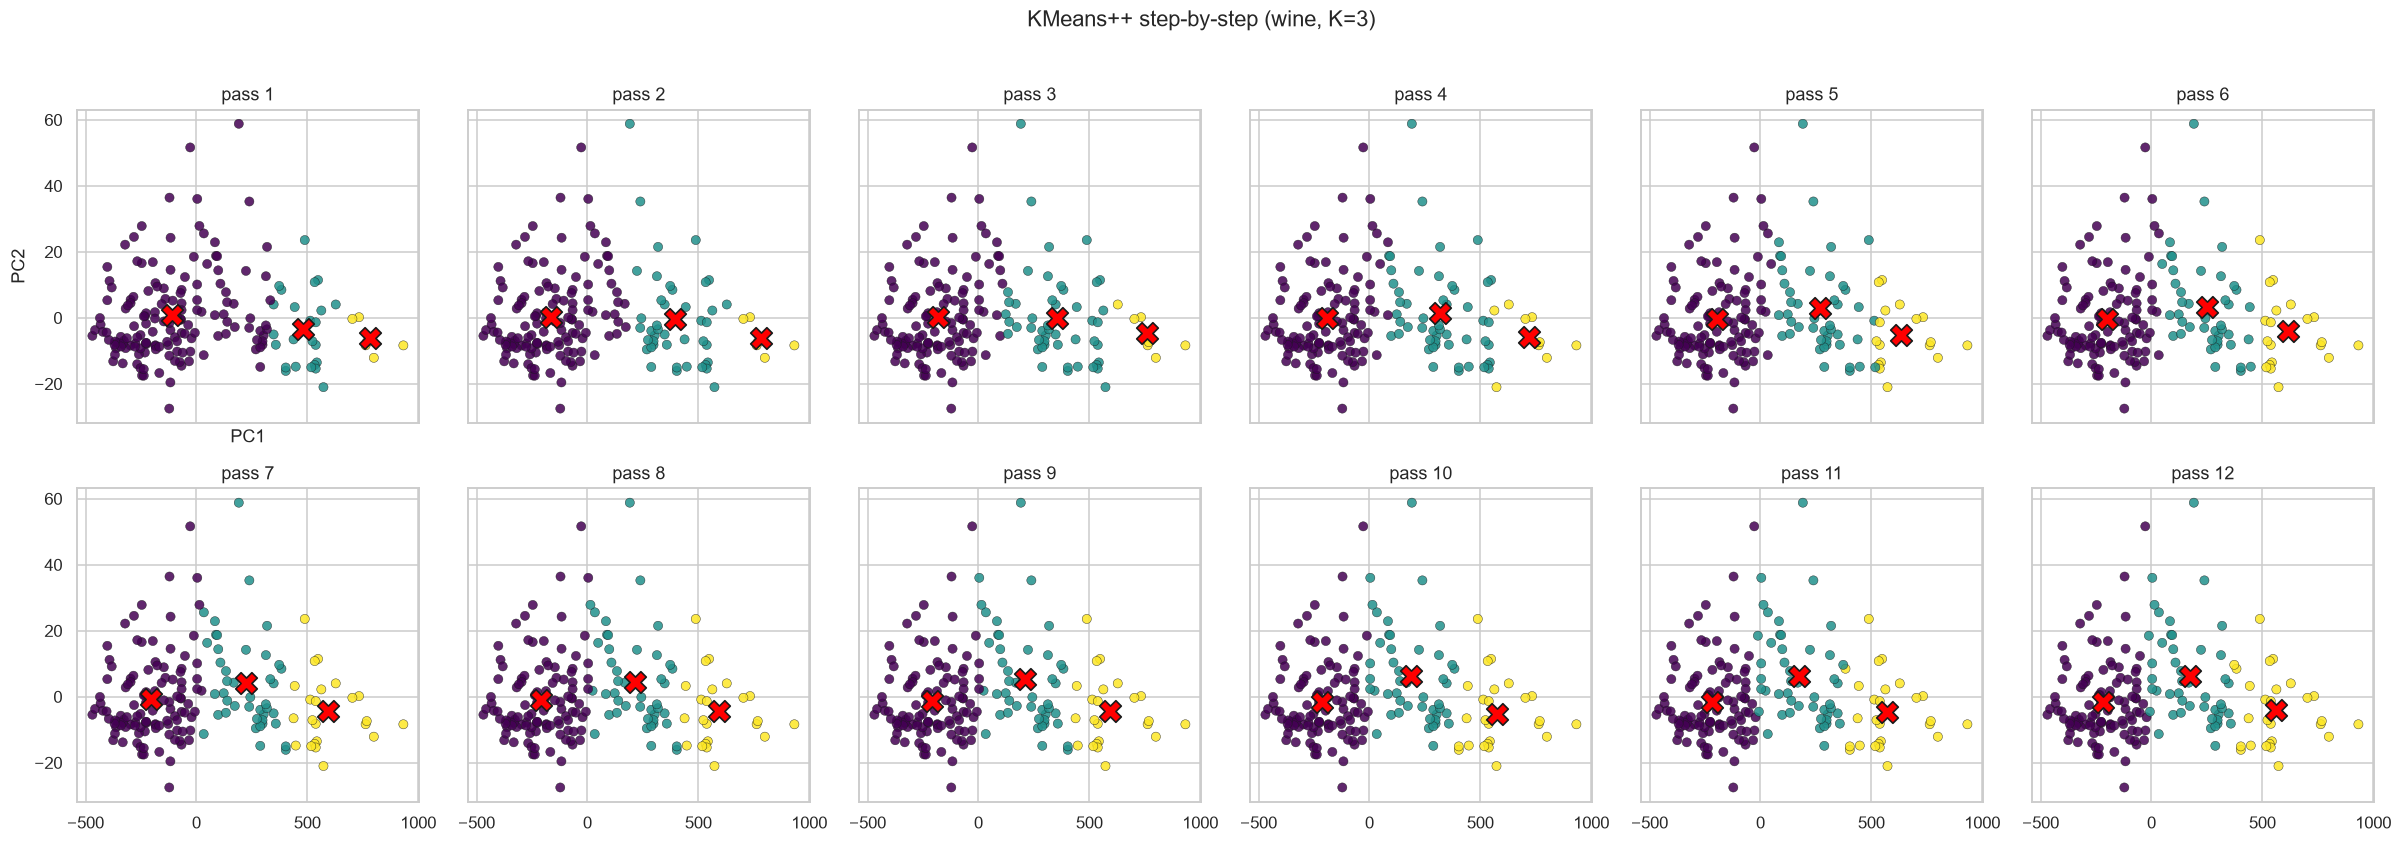

KMeans++ passes: 16


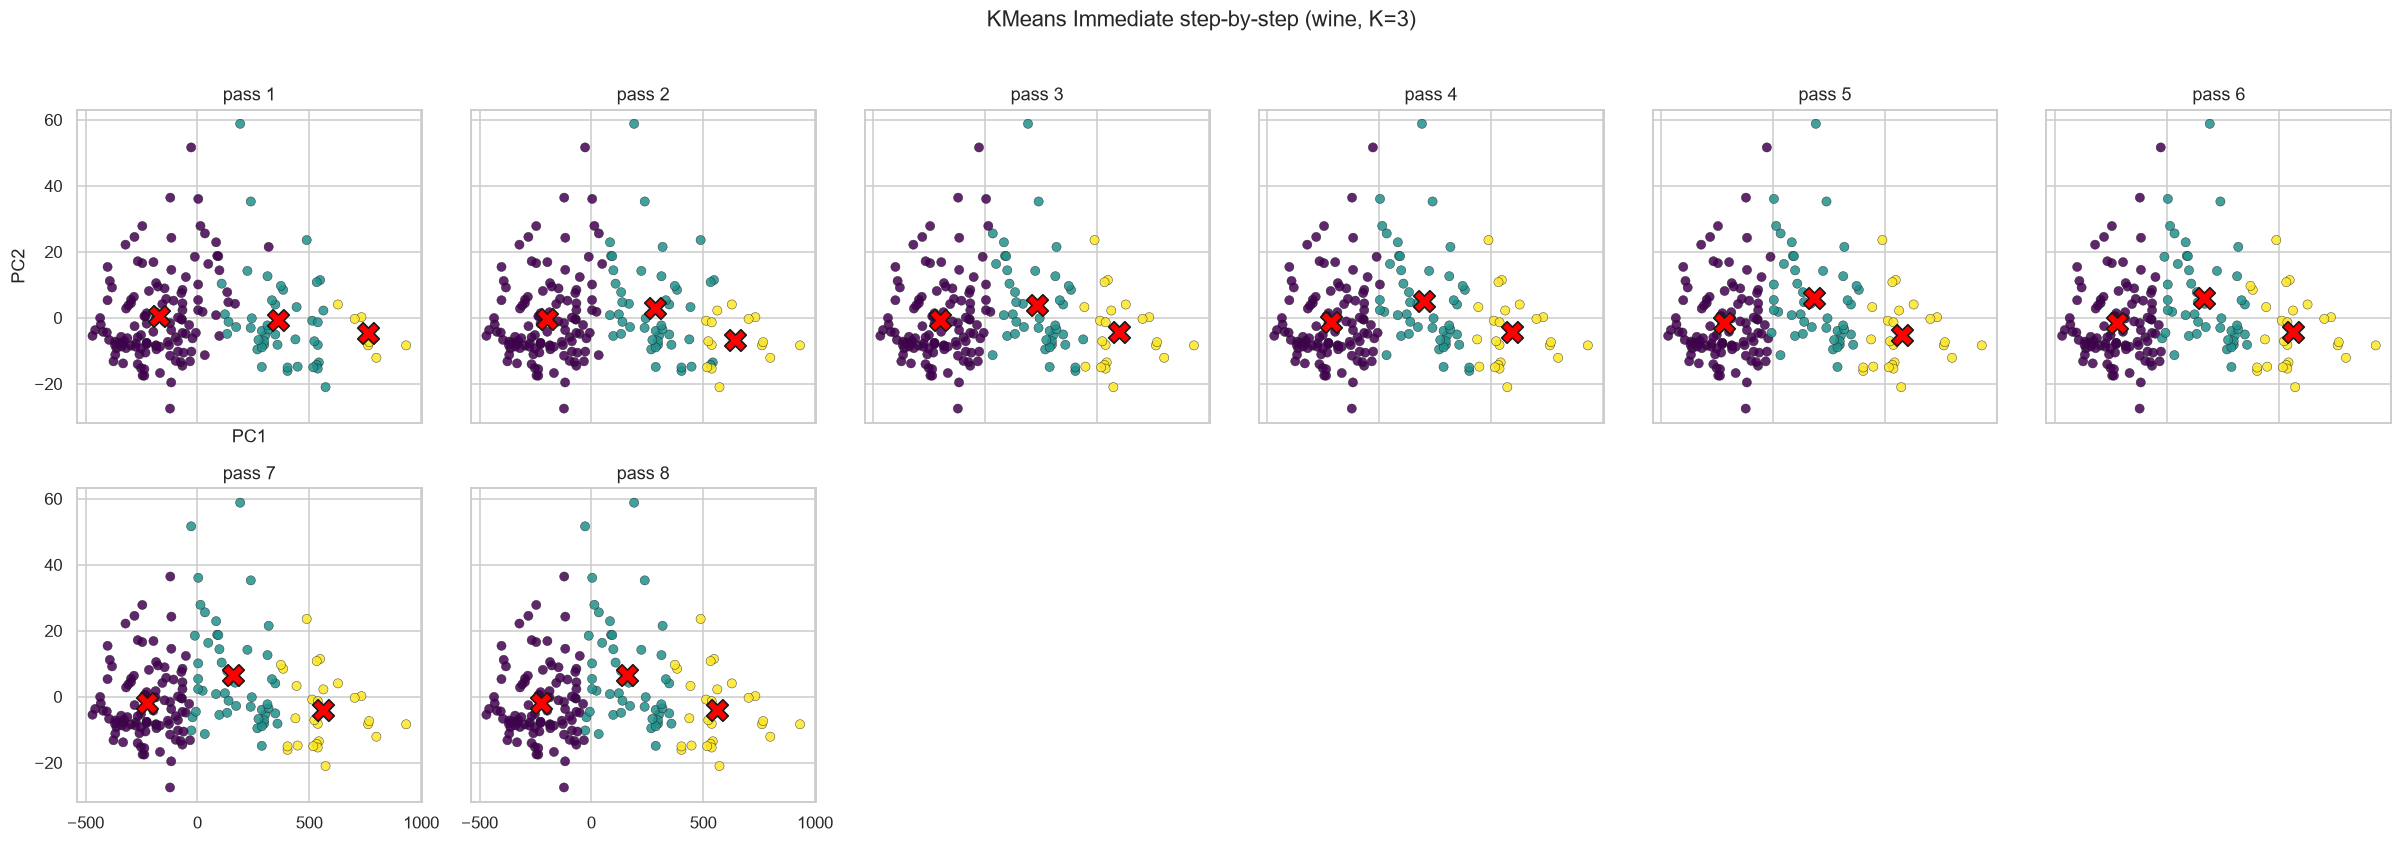

KMeans Immediate passes: 8


In [13]:
def conv_history(obj, X):
    obj.X = X
    obj.n = len(X)
    obj.n_feat = len(X[0])
    obj.centroids = pick_random_points(X, obj.K, obj.random_state)
    hist = []
    for it in range(obj.max_iters):
        obj.clusters = obj._assign(obj.centroids)
        lab = to_labels(obj.clusters, obj.n)
        old = [list(c) for c in obj.centroids]
        obj.centroids = obj._new_centroids(obj.clusters)
        hist.append((lab, [list(c) for c in obj.centroids]))
        if obj._done(old, obj.centroids):
            break
    return hist

def conv_history_imm(obj, X):
    obj.X = X
    obj.n = len(X)
    obj.n_feat = len(X[0])
    obj.centroids = pick_random_points(X, obj.K, obj.random_state)
    labels = [0] * len(X)
    hist = []
    for it in range(obj.max_iters):
        moved = False
        i = 0
        while i < len(X):
            nc = nearest_centroid(X[i], obj.centroids, obj.K)
            if nc != labels[i]:
                moved = True
                labels[i] = nc
            k = 0
            while k < obj.K:
                idxs = []
                j = 0
                while j < len(X):
                    if labels[j] == k:
                        idxs.append(j)
                    j = j + 1
                if len(idxs) != 0:
                    obj.centroids[k] = mean_of_points(X, idxs, len(X[0]))
                k = k + 1
            i = i + 1
        hist.append((labels[:], [list(c) for c in obj.centroids]))
        if not moved:
            break
    return hist

def conv_figure(hist, X, name, maxp=12):
    steps = min(len(hist), maxp)
    nrow, ncol = 2, 6
    _, axes = plt.subplots(nrow, ncol, figsize=(22, 7.5), sharex=True, sharey=True)
    axes = axes.ravel()
    j = 0
    while j < steps:
        a = axes[j]
        lab, C = hist[j]
        a.scatter(X[:,0], X[:,1], c=lab, cmap='viridis', s=36, edgecolor='k', linewidth=0.3, alpha=0.85)
        xs = [c[0] for c in C]
        ys = [c[1] for c in C]
        a.scatter(xs, ys, c='red', marker='X', s=200, edgecolor='k', linewidth=1.1, zorder=5)
        a.set_title('pass ' + str(j+1))
        j = j + 1
    j = steps
    while j < len(axes):
        axes[j].axis('off')
        j = j + 1
    axes[0].set_xlabel('PC1')
    axes[0].set_ylabel('PC2')
    plt.suptitle(name + ' step-by-step (wine, K=3)', y=1.02)
    plt.tight_layout()
    plt.show()
    return len(hist)

h1 = conv_history(KMeans(K=3, max_iters=150, random_state=3), X2)
n1 = conv_figure(h1, X2, 'KMeans')
print('KMeans passes:', n1)

h2 = conv_history(KMeansPP(K=3, max_iters=150, random_state=3), X2)
n2 = conv_figure(h2, X2, 'KMeans++')
print('KMeans++ passes:', n2)

h3 = conv_history_imm(KMeansImmediate(K=3, max_iters=150, random_state=3), X2)
n3 = conv_figure(h3, X2, 'KMeans Immediate')
print('KMeans Immediate passes:', n3)


## 8. Cluster Visualization (train)


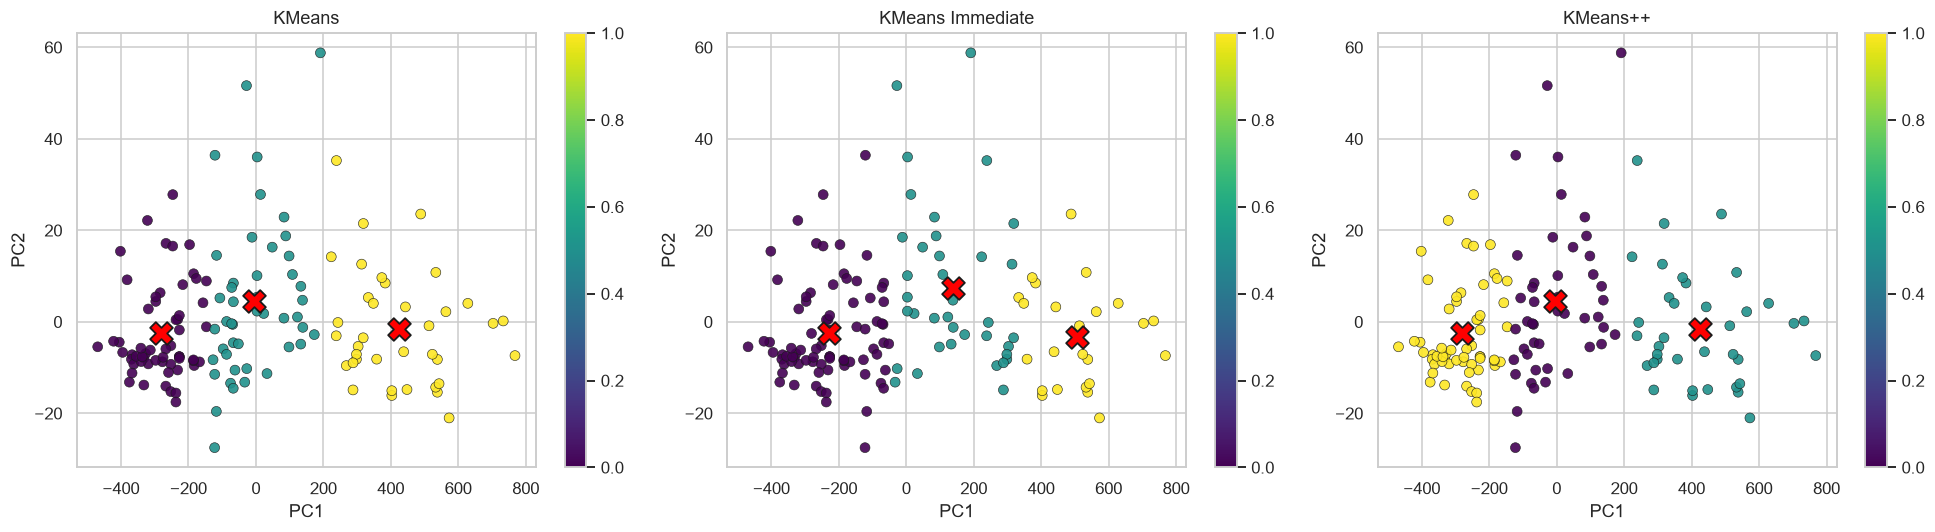

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5.0))
def draw(a, lab, C, title):
    a.scatter(Xtr[:, 0], Xtr[:, 1], c=lab, cmap='viridis', s=42, edgecolor='k', linewidth=0.4, alpha=0.9)
    a.scatter([c[0] for c in C], [c[1] for c in C], c='red', marker='X', s=220, edgecolor='k', linewidth=1.2, zorder=5)
    a.set_title(title); a.set_xlabel('PC1'); a.set_ylabel('PC2')
    fig.colorbar(plt.cm.ScalarMappable(norm=None, cmap='viridis'), ax=a)
draw(ax[0], ytr_km, km.centroids, 'KMeans')
draw(ax[1], ytr_kimm, kimm.centroids, 'KMeans Immediate')
draw(ax[2], ytr_kpp, kpp.centroids, 'KMeans++')
plt.tight_layout()
plt.show()


## 9. Predict Test Clusters


In [15]:
yte_km   = km.predict(Xte)
yte_kimm = kimm.predict(Xte)
yte_kpp  = kpp.predict(Xte)
print('KMeans    test labels:', yte_km)
print('KMeansImm test labels:', yte_kimm)
print('KMeansPP  test labels:', yte_kpp)


KMeans    test labels: [2, 1, 1, 0, 1, 2, 2, 0, 0, 1, 0, 0, 2, 1, 2, 0, 0, 1, 1, 2, 0, 1, 2, 2, 1, 0, 2, 0, 1, 1, 2, 1, 0, 0, 1, 1]
KMeansImm test labels: [2, 0, 1, 0, 0, 2, 2, 0, 0, 0, 0, 0, 2, 0, 2, 0, 0, 1, 1, 1, 0, 0, 1, 2, 0, 0, 2, 0, 0, 1, 1, 1, 0, 0, 0, 1]
KMeansPP  test labels: [1, 0, 0, 2, 0, 1, 1, 2, 2, 0, 2, 2, 1, 0, 1, 2, 2, 0, 0, 1, 2, 0, 1, 1, 0, 2, 1, 2, 0, 0, 1, 0, 2, 2, 0, 0]


## 10. Map Clusters to Wine Classes


In [16]:
def cluster_to_class_map(train_labels):
    m = {}
    for c in range(3):
        cnt = {}
        for i in range(len(Xtr)):
            if train_labels[i] == c:
                yv = ytr[i]
                cnt[yv] = cnt.get(yv, 0) + 1
        bestc = -1
        bestn = -1
        for yv, n in cnt.items():
            if n > bestn:
                bestn = n
                bestc = yv
        m[c] = bestc
    return m

m_km   = cluster_to_class_map(ytr_km)
m_kimm = cluster_to_class_map(ytr_kimm)
m_kpp  = cluster_to_class_map(ytr_kpp)
print('KMeans    cluster->class:', m_km)
print('KMeansImm cluster->class:', m_kimm)
print('KMeansPP  cluster->class:', m_kpp)


KMeans    cluster->class: {0: np.int64(1), 1: np.int64(2), 2: np.int64(0)}
KMeansImm cluster->class: {0: np.int64(1), 1: np.int64(0), 2: np.int64(0)}
KMeansPP  cluster->class: {0: np.int64(2), 1: np.int64(0), 2: np.int64(1)}


## 11. Accuracy, Precision, Recall, F1-Score


In [17]:
ytrp_km   = [m_km[l] for l in ytr_km]
ytep_km   = [m_km[l] for l in yte_km]
ytrp_kimm = [m_kimm[l] for l in ytr_kimm]
ytep_kimm = [m_kimm[l] for l in yte_kimm]
ytrp_kpp  = [m_kpp[l] for l in ytr_kpp]
ytep_kpp  = [m_kpp[l] for l in yte_kpp]

def report(name, ytrp, ytep):
    print('---', name, '---')
    print('Training Accuracy:', round(accuracy_score(ytr, ytrp), 2))
    print('Testing Accuracy:', round(accuracy_score(yte, ytep), 2))
    print('Precision:', round(precision_score(yte, ytep, average='weighted', zero_division=0), 2))
    print('Recall:', round(recall_score(yte, ytep, average='weighted', zero_division=0), 2))
    print('F1-Score:', round(f1_score(yte, ytep, average='weighted', zero_division=0), 2))

report('KMeans', ytrp_km, ytep_km)
report('KMeans Immediate', ytrp_kimm, ytep_kimm)
report('KMeans++', ytrp_kpp, ytep_kpp)


--- KMeans ---
Training Accuracy: 0.68
Testing Accuracy: 0.72
Precision: 0.76
Recall: 0.72
F1-Score: 0.73
--- KMeans Immediate ---
Training Accuracy: 0.67
Testing Accuracy: 0.69
Precision: 0.5
Recall: 0.69
F1-Score: 0.58
--- KMeans++ ---
Training Accuracy: 0.68
Testing Accuracy: 0.72
Precision: 0.76
Recall: 0.72
F1-Score: 0.73


## 12. Confusion Matrix


KMeans    cm:
[[10  0  2]
 [ 0  9  5]
 [ 0  3  7]]
KMeansImm cm:
[[12  0  0]
 [ 1 13  0]
 [ 3  7  0]]
KMeansPP  cm:
[[10  0  2]
 [ 0  9  5]
 [ 0  3  7]]


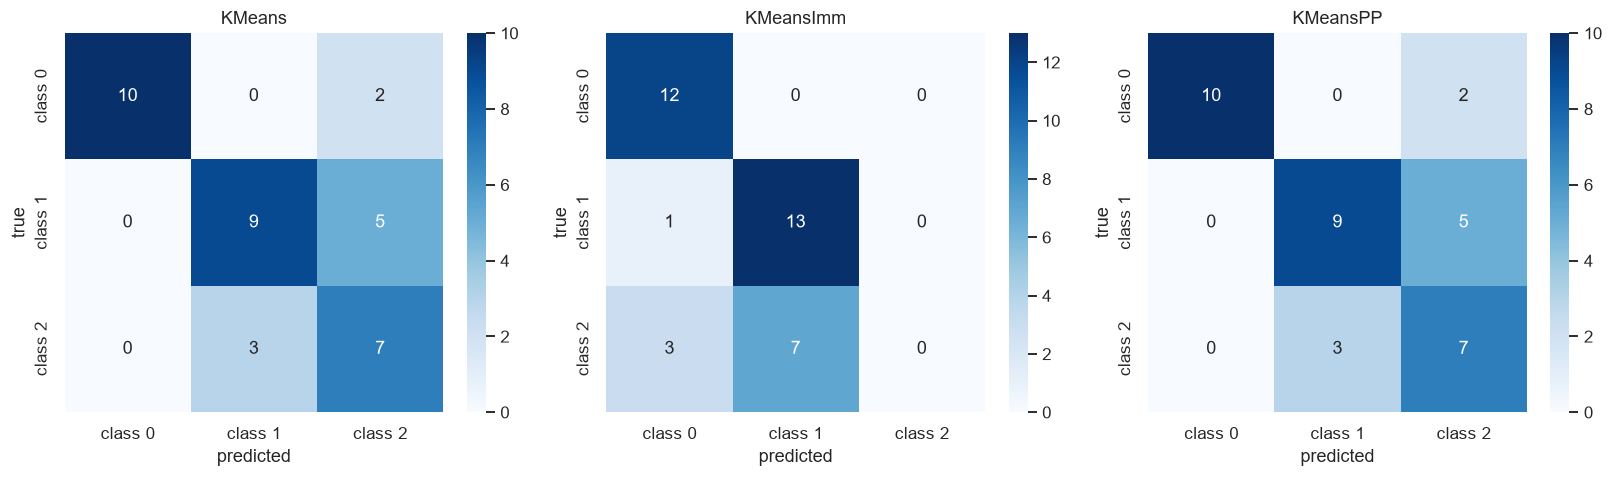

In [18]:
cm_km   = confusion_matrix(yte, ytep_km,   labels=[0,1,2])
cm_kimm = confusion_matrix(yte, ytep_kimm, labels=[0,1,2])
cm_kpp  = confusion_matrix(yte, ytep_kpp,  labels=[0,1,2])
print('KMeans    cm:');  print(cm_km)
print('KMeansImm cm:');  print(cm_kimm)
print('KMeansPP  cm:');  print(cm_kpp)

fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
xt = ['class 0', 'class 1', 'class 2']
for a, cm, name in [(ax[0], cm_km, 'KMeans'), (ax[1], cm_kimm, 'KMeansImm'), (ax[2], cm_kpp, 'KMeansPP')]:
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=xt, yticklabels=xt, ax=a)
    a.set_xlabel('predicted'); a.set_ylabel('true'); a.set_title(name)
plt.tight_layout()
plt.show()


## 13. Silhouette Score and Cluster Metrics (full data)


In [19]:
km  = KMeans(K=3, max_iters=150, random_state=3)
y_km = km.fit(X2)
ari = adjusted_rand_score(yw, y_km)
nmi = normalized_mutual_info_score(yw, y_km)
sil = silhouette_score(X2, y_km)
print('KMeans     ' '  ARI:', round(ari, 2), ' NMI:', round(nmi, 2), ' Silhouette:', round(sil, 2))

kimm = KMeansImmediate(K=3, max_iters=150, random_state=3)
y_kimm = kimm.fit(X2)
ari = adjusted_rand_score(yw, y_kimm)
nmi = normalized_mutual_info_score(yw, y_kimm)
sil = silhouette_score(X2, y_kimm)
print('KMeansImm  ' '  ARI:', round(ari, 2), ' NMI:', round(nmi, 2), ' Silhouette:', round(sil, 2))

kpp = KMeansPP(K=3, max_iters=150, random_state=3)
y_kpp = kpp.fit(X2)
ari = adjusted_rand_score(yw, y_kpp)
nmi = normalized_mutual_info_score(yw, y_kpp)
sil = silhouette_score(X2, y_kpp)
print('KMeansPP   ' '  ARI:', round(ari, 2), ' NMI:', round(nmi, 2), ' Silhouette:', round(sil, 2))


KMeans       ARI: 0.35  NMI: 0.42  Silhouette: 0.56
KMeansImm    ARI: 0.35  NMI: 0.42  Silhouette: 0.56
KMeansPP     ARI: 0.35  NMI: 0.42  Silhouette: 0.56


## 14. Compare with sklearn KMeans++


In [20]:
from sklearn.cluster import KMeans as SKKMeans

sk = SKKMeans(n_clusters=3, n_init=10, random_state=0).fit(X2)
print('sklearn KMeans++ inertia:', sk.inertia_)
ari = adjusted_rand_score(list(sk.labels_), y_kpp)
nmi = normalized_mutual_info_score(list(sk.labels_), y_kpp)
sil = silhouette_score(X2, y_kpp)
print('vs sklearn ' '  ARI:', round(ari, 2), ' NMI:', round(nmi, 2), ' Silhouette:', round(sil, 2))


sklearn KMeans++ inertia: 2367716.086106179
vs sklearn   ARI: 0.42  NMI: 0.53  Silhouette: 0.56


## 15. Final Cluster Plot (full data)


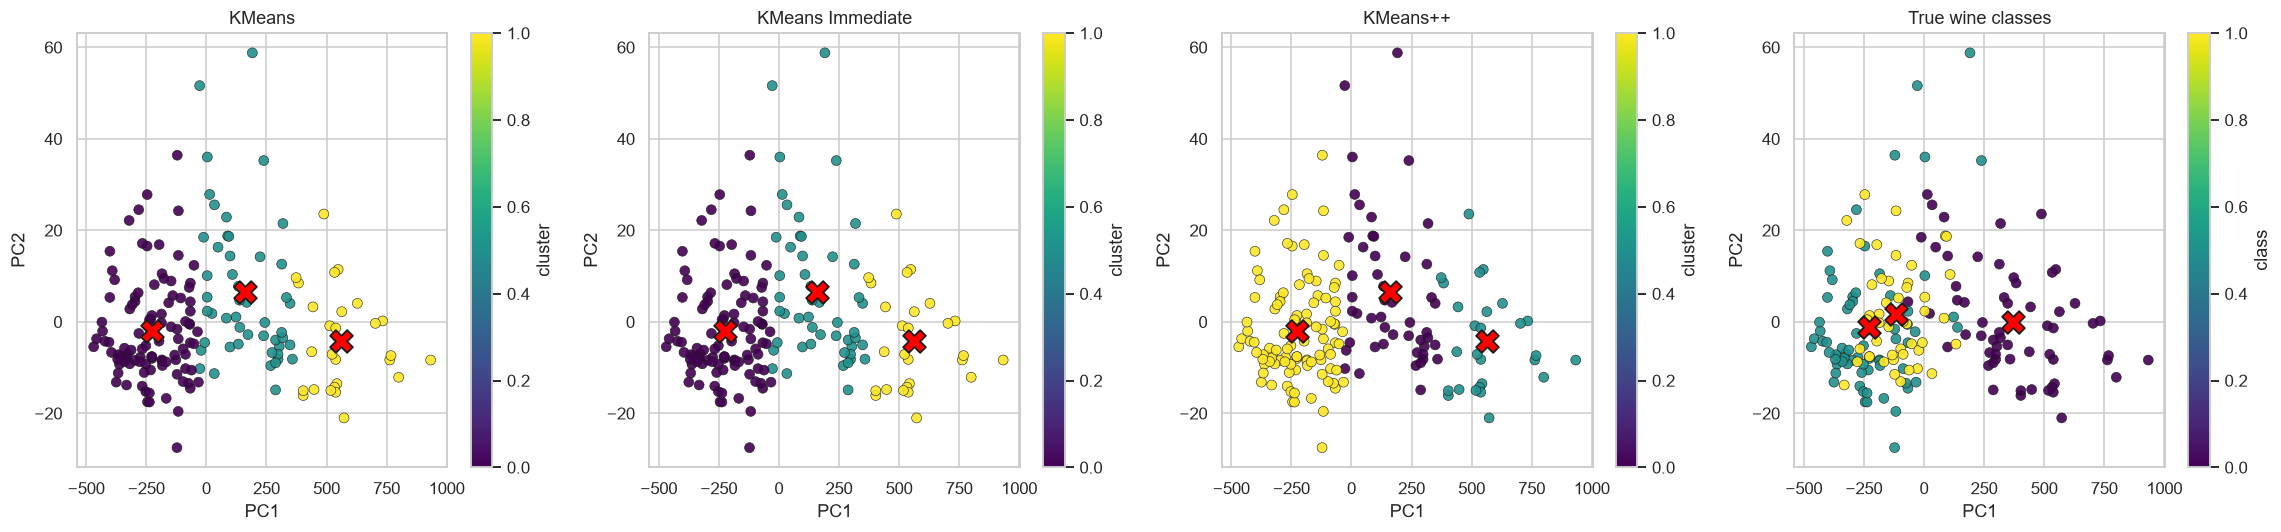

In [21]:
fig, ax = plt.subplots(1, 4, figsize=(21, 5.0))

def draw(a, lab, C, title, tag):
    a.scatter(X2[:, 0], X2[:, 1], c=lab, cmap='viridis', s=42, edgecolor='k', linewidth=0.4, alpha=0.9)
    a.scatter([c[0] for c in C], [c[1] for c in C], c='red', marker='X', s=220, edgecolor='k', linewidth=1.2, zorder=5)
    a.set_title(title); a.set_xlabel('PC1'); a.set_ylabel('PC2')
    fig.colorbar(plt.cm.ScalarMappable(norm=None, cmap='viridis'), ax=a, label=tag)

draw(ax[0], y_km, km.centroids, 'KMeans', 'cluster')
draw(ax[1], y_kimm, kimm.centroids, 'KMeans Immediate', 'cluster')
draw(ax[2], y_kpp, kpp.centroids, 'KMeans++', 'cluster')

truec = []
for c in [0, 1, 2]:
    pts = X2[np.array(yw) == c]
    truec.append(pts.mean(axis=0))
draw(ax[3], yw, truec, 'True wine classes', 'class')

plt.tight_layout()
plt.show()